In [1]:
from utils import *
import numpy as np
import matplotlib.pyplot as plt
import copy

# Overfitting and Regularization

In this script, we'll test regularization techniques like weight-decay and dropout. It will use the updated instance of the Neural Network in utils.py as well as the updated training loop. 

TODO: make loss an attribute of the NN and not a method. Keep the losses outside the NN. We'll start by initializing a random NN with softmax output layer and log-likelihood loss to follow Nielsen closely. But then, where's the sigmoid? First, we'll test how bad overfitting is when we have only a limited amount of data.

shape of raw training inputs x:  (50000, 784) 
shape of raw training labels y:  (50000,)


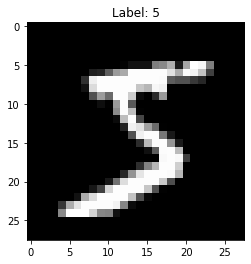

shape of x_train : (784, 50000)
shape of y_train : (10, 50000)


In [2]:
import pickle
import gzip

with gzip.open('neural-networks-and-deep-learning-master/data/mnist.pkl.gz', 'rb') as f:
    training_data, validation_data, test_data = pickle.load(f, encoding='latin1')

print('shape of raw training inputs x: ',training_data[0].shape, '\nshape of raw training labels y: ', training_data[1].shape)   # (50000, 784) (50000,)

first_image = training_data[0][0]
first_label = training_data[1][0]

# Reshape the first image to 28x28 pixels
image = first_image.reshape(28, 28)

# Display the image
plt.imshow(image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()

# Extract labels and training images from training_data
y_labels = training_data[1]
x_train = training_data[0].T

# Extract validation data
y_labels_val = validation_data[1]
x_val = validation_data[0].T

print('shape of x_train :',x_train.shape) # (728, 50000)
d = len(y_labels)

y_train = labels_to_onehot(y_labels)
y_val = labels_to_onehot(y_labels_val)

print('shape of y_train :',y_train.shape) # (728, 50000)

# Organize training data
train_data = (x_train, y_train)
val_data = (x_val, y_val)

Now we can initialize a Network and train it with no regularization on this training set

In [3]:
spec = [784, 30, 10]
act, del_act = [ReLU], [del_ReLU]

net = network(spec, activation=act, del_activation=del_act) 

# Compute initial accuracy of the network
print('initial accuracy', compute_accuracy(net, x_train, train_data[1]))

initial accuracy 0.070068


Train the neural network with no regularization and a reduced dataset of only 1000 samples

In [21]:
epochs = 400
eta = 0.05

net_copy = copy.deepcopy(net)

net_unreg, train_loss_unreg, val_loss_unreg, train_acc_unreg, val_acc_unreg = train(net_copy, (x_train[:,:1000], y_train[:,:1000]), val_data, epochs=epochs, eta=eta, lam=0,verbose=False)

Initial Training Loss 2.3546272590076716


100%|██████████| 400/400 [01:44<00:00,  3.82it/s]


Plot train and validation accuracies and CE loss

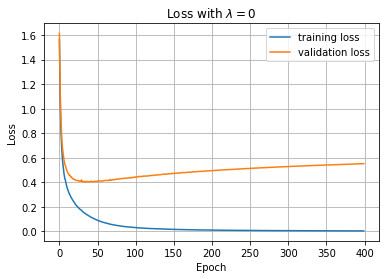

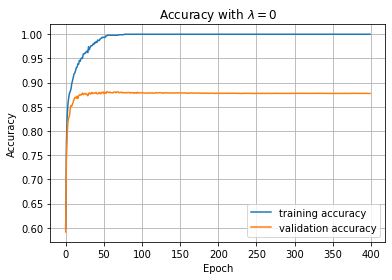

In [22]:
plot_loss(train_loss_unreg, val_loss_unreg, title='Loss with $\lambda = 0$')
plot_accuracies(train_acc_unreg, val_acc_unreg, title='Accuracy with $\lambda = 0$')


We see some clear overfitting behaviour. Moreover, it's interesting that in this network with only one hidden layer and softmax + log-likelihood loss the epoch at which the validation loss starts to increase (~30) is also the epoch at which the accuracy of prediction in the validation set starts to saturate at ~87%. 

What if we take the same network with trained overfitted weights and train it with the regularized loss?  

In [14]:

net_reg, train_loss_reg, val_loss_reg, train_acc_reg, val_acc_reg = train(net_unreg, (x_train[:,:1000], y_train[:,:1000]), val_data, epochs=epochs, eta=eta, lam=0.1,verbose=False)

Initial Training Loss 0.004113157453031762


100%|██████████| 400/400 [02:23<00:00,  2.78it/s]


Plot accuracies and losses on this network

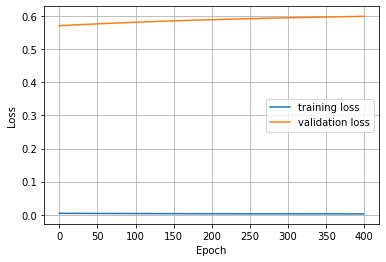

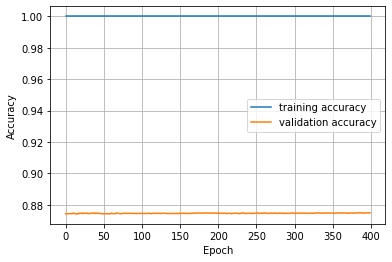

In [15]:
plot_loss(train_loss_reg, val_loss_reg)#, title='Loss with $\lambda = 0.1$')
plot_accuracies(train_acc_reg, val_acc_reg)# title='Accuracy with $\lamdba = 0.1$')

So it seems that we cannot _correct_ an overfitted network by retraining its parameters. Seems that we are trapped in a local minimum. 
What if we take the original (untrained) network and train it with the regularized objective? 

In [10]:
net_copy = copy.deepcopy(net)

net_reg, train_loss_reg, val_loss_reg, train_acc_reg, val_acc_reg = train(net_copy, (x_train[:,:1000], y_train[:,:1000]), val_data, epochs=epochs, eta=eta, lam=10,verbose=False)

Initial Training Loss 2.3546272590076716


100%|██████████| 400/400 [01:47<00:00,  3.73it/s]


Plot results

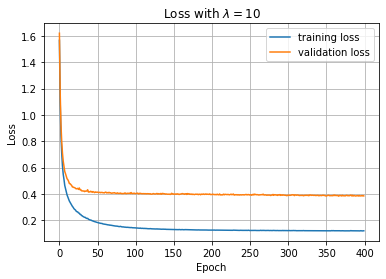

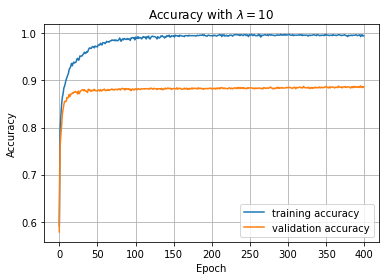

In [12]:
plot_loss(train_loss_reg, val_loss_reg, title='Loss with $\lambda = 10$')
plot_accuracies(train_acc_reg, val_acc_reg, title='Accuracy with $\lambda = 10$')

Does the accuracy keep growing after saturating? 

In [24]:
print('Final validation accuracy reached in the unregularized net', val_acc_unreg[-1] * 100, '%')
print('Final validation accuracy reached in the regularized net', val_acc_reg[-1] * 100, '%')

print('Saturated accuracy change in the unregularized case', (val_acc_unreg[-1] - val_acc_unreg[200]) * 100,  '%')
print('Saturated accuracy change in the regularized case', (val_acc_reg[-1] - val_acc_reg[200]) * 100,  '%')

Final validation accuracy reached in the unregularized net 87.77000000000001 %
Final validation accuracy reached in the regularized net 88.62 %
Saturated accuracy change in the unregularized case 0.0 %
Saturated accuracy change in the regularized case 0.29000000000000137 %


We can loop over regularization parameters to see what performs best in this small network with reduced data

Initial Training Loss 2.3546272590076716


100%|██████████| 50/50 [00:12<00:00,  3.89it/s]


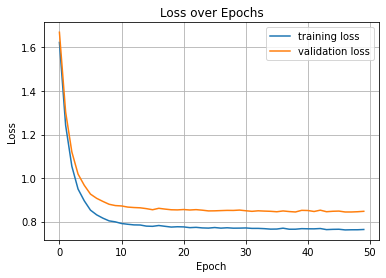

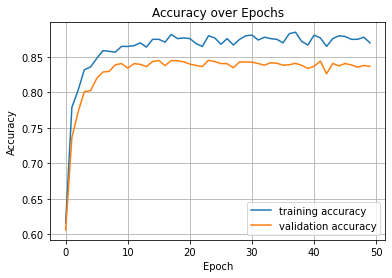

accuracy for lam = 100 : 0.8368
Initial Training Loss 2.3546272590076716


100%|██████████| 50/50 [00:13<00:00,  3.65it/s]


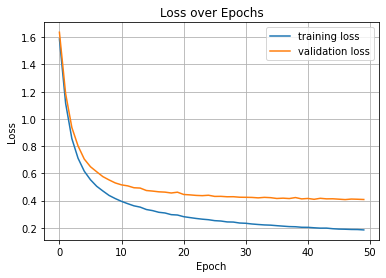

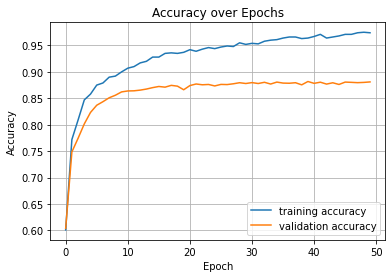

accuracy for lam = 10 : 0.881
Initial Training Loss 2.3546272590076716


100%|██████████| 50/50 [00:13<00:00,  3.83it/s]


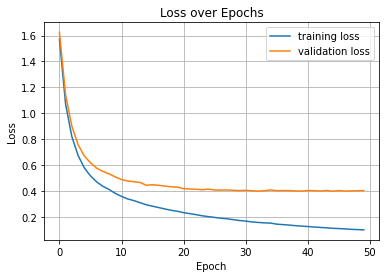

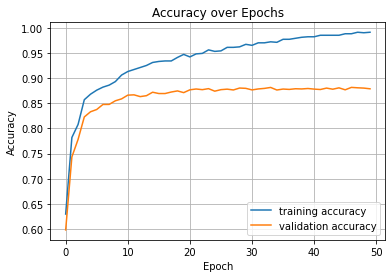

accuracy for lam = 1 : 0.8787
Initial Training Loss 2.3546272590076716


100%|██████████| 50/50 [00:14<00:00,  3.38it/s]


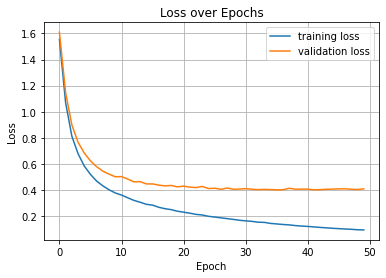

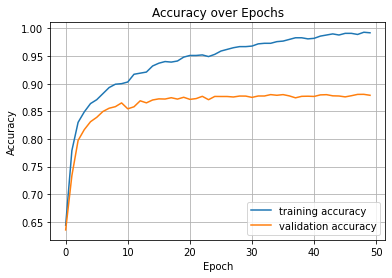

accuracy for lam = 0.1 : 0.879
Initial Training Loss 2.3546272590076716


100%|██████████| 50/50 [00:14<00:00,  3.53it/s]


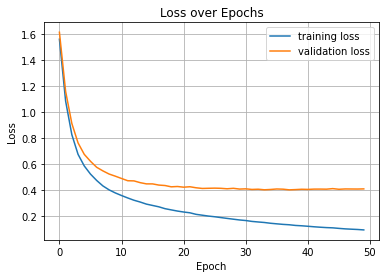

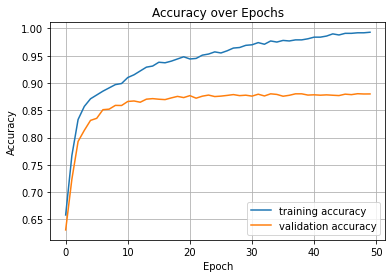

accuracy for lam = 0.01 : 0.8799
[0.8368 0.881  0.8787 0.879  0.8799]


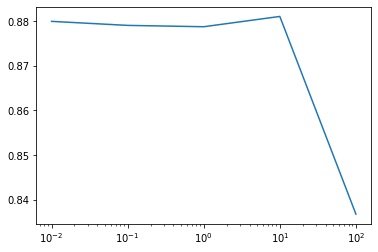

In [18]:
epochs = 50
eta = 0.05
lams = [1000, 100, 10, 1, 0.1, 0.01]
accuracies = np.zeros(len(lams))

# Just include first 1000 samples in training
reduced_train_data = (x_train[:,:1000], y_train[:,:1000])

# Same initialization -> Same initial condition

for i in range(len(lams)):
    Ni = copy.deepcopy(net) 
    Ni, train_losses, val_losses, train_acc, val_acc = train(Ni, reduced_train_data, val_data, epochs=epochs, eta=eta, verbose=False, lam=lams[i])
    plot_loss(train_losses, val_losses)
    plot_accuracies(train_acc, val_acc)
    accuracies[i] = compute_accuracy(Ni, x_val, y_labels_val)
    print('accuracy for lam =', lams[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(lams, accuracies)

Now we can try to do the same when training on the full dataset instead of only 1000 datapoints

Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [01:43<00:00,  2.07s/it]


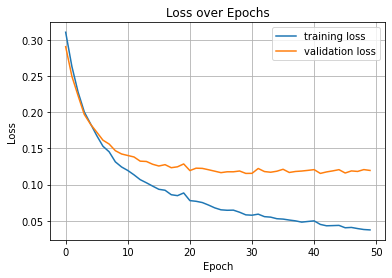

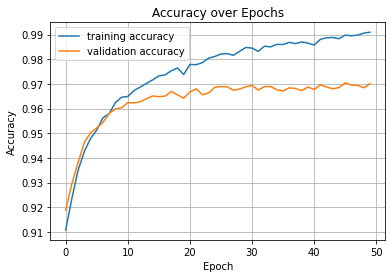

accuracy for lam = 0 : 0.9701
Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [01:40<00:00,  2.00s/it]


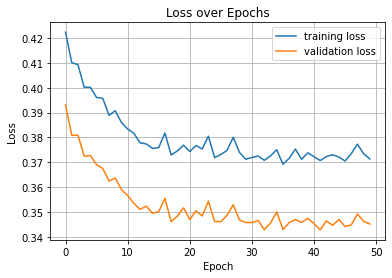

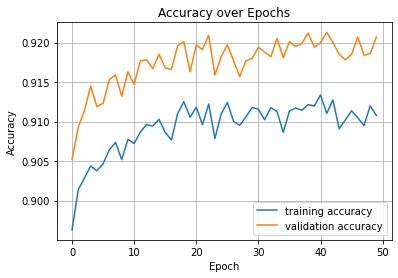

accuracy for lam = 1000 : 0.9207
Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [01:45<00:00,  2.11s/it]


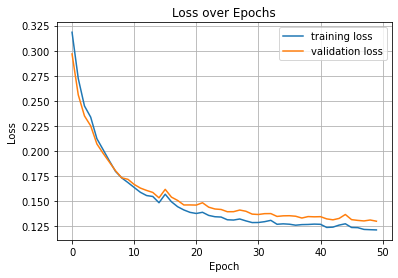

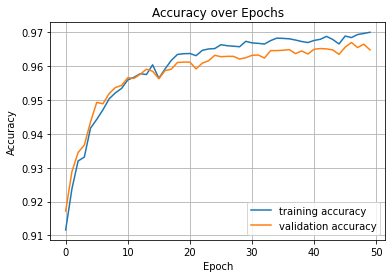

accuracy for lam = 100 : 0.9648
Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [02:05<00:00,  2.51s/it]


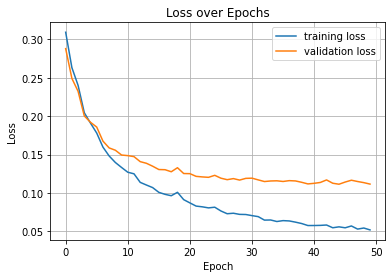

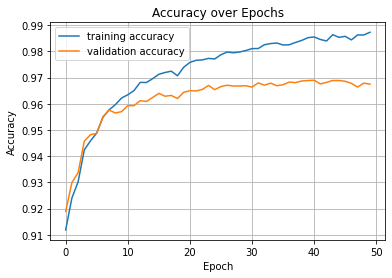

accuracy for lam = 10 : 0.9675
Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [02:04<00:00,  2.49s/it]


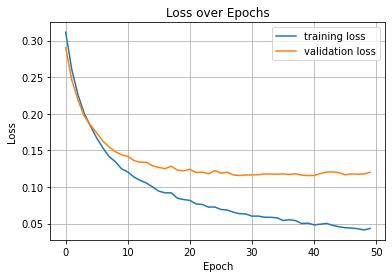

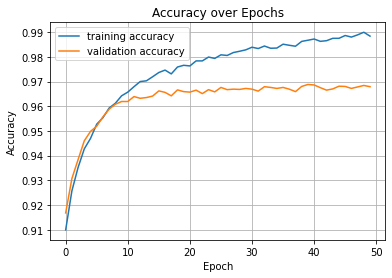

accuracy for lam = 1 : 0.9679
Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [02:13<00:00,  2.68s/it]


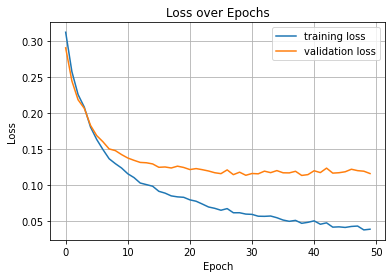

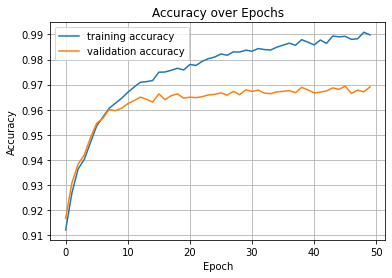

accuracy for lam = 0.1 : 0.9691
Initial Training Loss 2.336441252678803


100%|██████████| 50/50 [02:04<00:00,  2.49s/it]


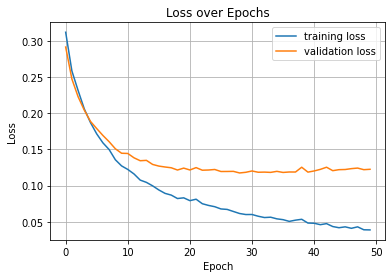

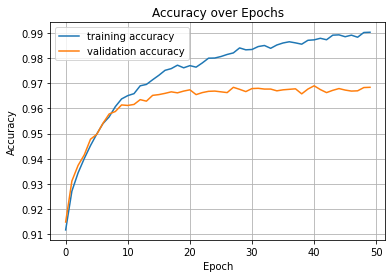

accuracy for lam = 0.01 : 0.9684
[0.9701 0.9207 0.9648 0.9675 0.9679 0.9691 0.9684]


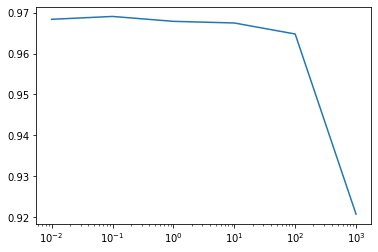

In [19]:
epochs = 50
eta = 0.05
lams = [0, 1000, 100, 10, 1, 0.1, 0.01]
accuracies = np.zeros(len(lams))

# Same initialization -> Same initial condition

for i in range(len(lams)):
    Ni = copy.deepcopy(net) 
    Ni, train_losses, val_losses, train_acc, val_acc = train(Ni, train_data, val_data, epochs=epochs, eta=eta, verbose=False, lam=lams[i])
    plot_loss(train_losses, val_losses)
    plot_accuracies(train_acc, val_acc)
    accuracies[i] = compute_accuracy(Ni, x_val, y_labels_val)
    print('accuracy for lam =', lams[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(lams[1:], accuracies[1:])

I still get the best results in the unregularized case! Could be that the training data is broad enough. However, if we look at the plot of lam=100, it seems that the accuracy is far from saturated! We can try this run again with more epochs to see if we reach saturation at a later point and hopefully get a petter accuracy than in the unregularized case.  

Initial Training Loss 2.336441252678803


100%|██████████| 100/100 [03:10<00:00,  1.91s/it]


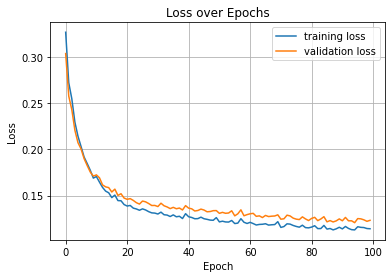

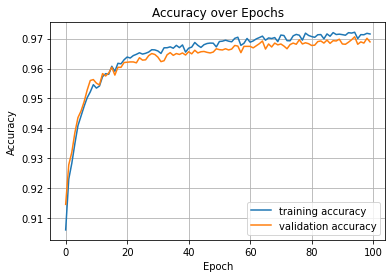

In [25]:
N100 = copy.deepcopy(net) 
N100, train_losses_100, val_losses_100, train_acc_100, val_acc_100 = train(N100, train_data, val_data, epochs=100, eta=eta, verbose=False, lam=100)
plot_loss(train_losses_100, val_losses_100)
plot_accuracies(train_acc_100, val_acc_100)

This looks like a very healthy training curve. Validation and training accuracy look almost the same. This is an indication that we are really picking up features from our dataset instead of memorizing peculiarities of the training data to reduce the training CE loss. We can now do a search around 100 to see if we can outperform the unregularized network

Initial Training Loss 2.336441252678803


100%|██████████| 70/70 [02:40<00:00,  2.29s/it]


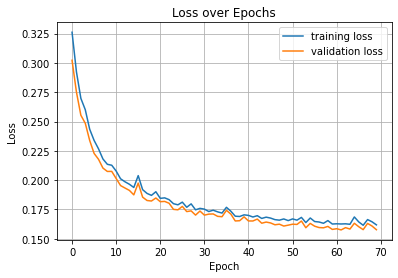

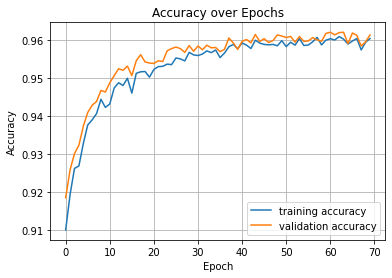

accuracy for lam = 200 : 0.9613
Initial Training Loss 2.336441252678803


100%|██████████| 70/70 [02:31<00:00,  2.17s/it]


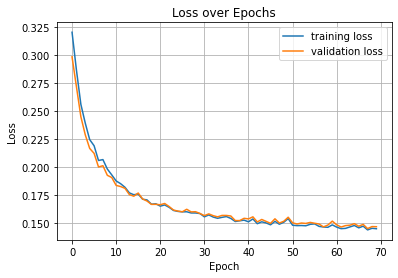

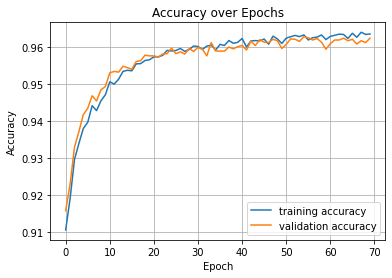

accuracy for lam = 150 : 0.9625
Initial Training Loss 2.336441252678803


100%|██████████| 70/70 [03:03<00:00,  2.62s/it]


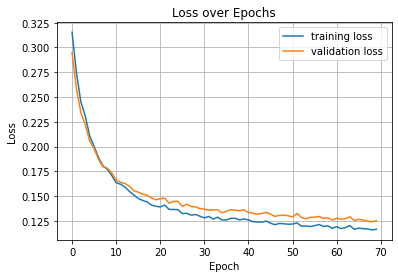

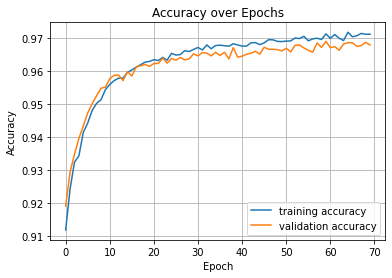

accuracy for lam = 100 : 0.9679
Initial Training Loss 2.336441252678803


100%|██████████| 70/70 [14:54<00:00, 12.79s/it] 


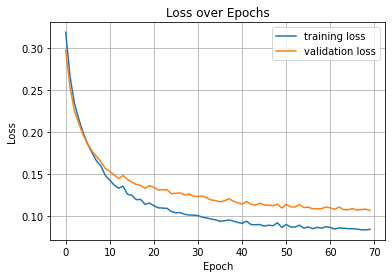

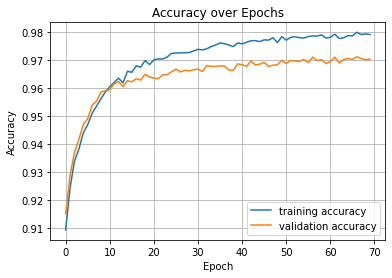

accuracy for lam = 50 : 0.9703
Initial Training Loss 2.336441252678803


100%|██████████| 70/70 [02:44<00:00,  2.36s/it]


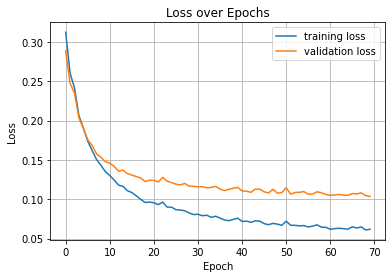

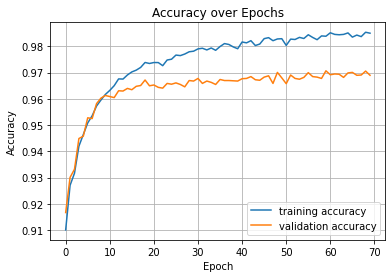

accuracy for lam = 25 : 0.969
Initial Training Loss 2.336441252678803


100%|██████████| 70/70 [02:41<00:00,  2.31s/it]


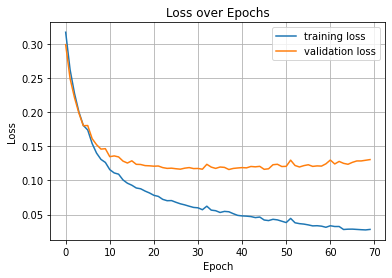

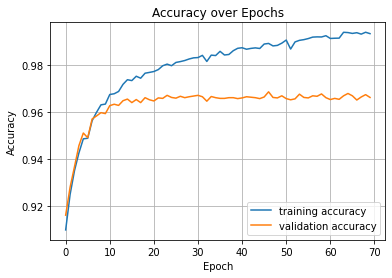

accuracy for lam = 0 : 0.9663
[0.9613 0.9625 0.9679 0.9703 0.969  0.9663]


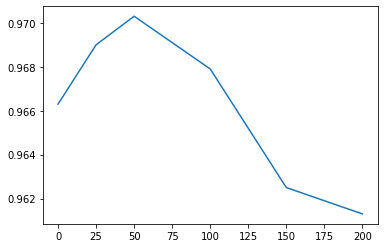

In [32]:
epochs = 70
eta = 0.05
lams = [200, 150, 100, 50, 25, 0]
accuracies = np.zeros(len(lams))

# Same initialization -> Same initial condition

for i in range(len(lams)):
    Ni = copy.deepcopy(net) 
    Ni, train_losses, val_losses, train_acc, val_acc = train(Ni, train_data, val_data, epochs=epochs, eta=eta, verbose=False, lam=lams[i])
    plot_loss(train_losses, val_losses)
    plot_accuracies(train_acc, val_acc)
    accuracies[i] = compute_accuracy(Ni, x_val, y_labels_val)
    print('accuracy for lam =', lams[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.plot(lams, accuracies)

It seems like lam=150 is great because the train and validation accuracies track each other almost perfectly and sit on top of each other across all epochs. However, we see that having _lower_ values of lambda actually helps us reach a higher validation accuracy. So maybe it's good to overfit just a little: the training accuracy pulls the validation accuracy higher although not at the same height. The optimal value seems to be around lam=25

Now we can look at an regularized net with hidden layers and ReLU activations. _tour de force_

In [29]:
deep_spec = [784, 256, 64, 10]
act = [ReLU]
del_act = [del_ReLU]

deep_net = network(deep_spec, act, del_act)

initial_accuracy = compute_accuracy(deep_net, x_train, training_data[1])
print('Initial accuracy of the deep net', initial_accuracy)

Initial accuracy of the deep net 0.1451


Now we can train the deep net over 100 epochs with a regularization of lam = 100

Initial Training Loss 2.3293692608023355


100%|██████████| 100/100 [07:30<00:00,  4.51s/it]


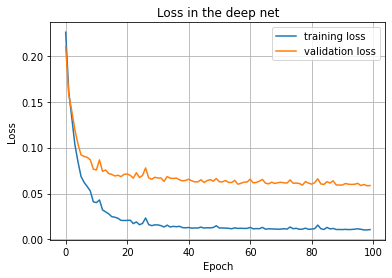

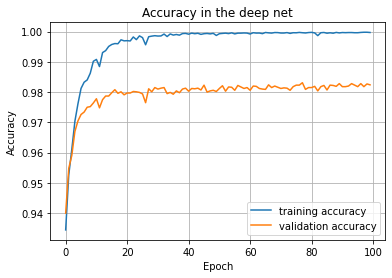

Final validation accuracy in the deep net : 98.24000000000001 %


In [34]:
trained_deep_net = copy.deepcopy(deep_net) 
trained_deep_net, train_losses_deep, val_losses_deep, train_acc_deep, val_acc_deep = train(trained_deep_net, train_data, val_data, epochs=100, eta=eta, verbose=False, lam=25)
plot_loss(train_losses_deep, val_losses_deep, title='Loss in the deep net')
plot_accuracies(train_acc_deep, val_acc_deep, title='Accuracy in the deep net')
print('Final validation accuracy in the deep net :',val_acc_deep[-1] * 100, '%')

What happens with 0 regularization?

Initial Training Loss 2.3293692608023355


100%|██████████| 100/100 [07:36<00:00,  4.56s/it]


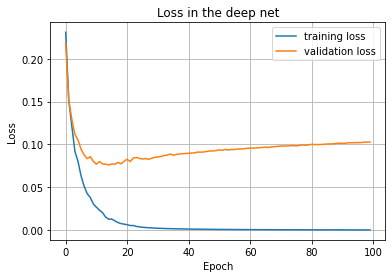

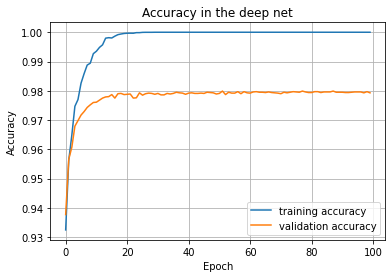

Final validation accuracy in the deep net : 97.92999999999999 %


In [33]:
train_deep_net = copy.deepcopy(deep_net) 
train_deep_net, train_losses_deep, val_losses_deep, train_acc_deep, val_acc_deep = train(train_deep_net, train_data, val_data, epochs=100, eta=eta, verbose=False, lam=0)
plot_loss(train_losses_deep, val_losses_deep, title='Loss in the deep net')
plot_accuracies(train_acc_deep, val_acc_deep, title='Accuracy in the deep net')
print('Final validation accuracy in the deep net :',val_acc_deep[-1] * 100, '%')